[*********************100%***********************]  1 of 1 completed


Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 118ms/step - loss: 0.6663 - val_loss: 3.5365
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - loss: 0.6625 - val_loss: 3.5090
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - loss: 0.6598 - val_loss: 3.4947
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - loss: 0.6594 - val_loss: 3.4877
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - loss: 0.6598 - val_loss: 3.4806
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - loss: 0.6588 - val_loss: 3.4735
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - loss: 0.6590 - val_loss: 3.4620
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - loss: 0.6568 - val_loss: 3.4481
Epoch 9/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - loss: 0.6567 - val_loss: 3.4287
Epoch 10/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - loss: 0.6568 - val_loss: 3.4217
Epoch 11/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - loss: 0.6548 - val_loss: 3.4167
Epoch 12/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - loss: 0.

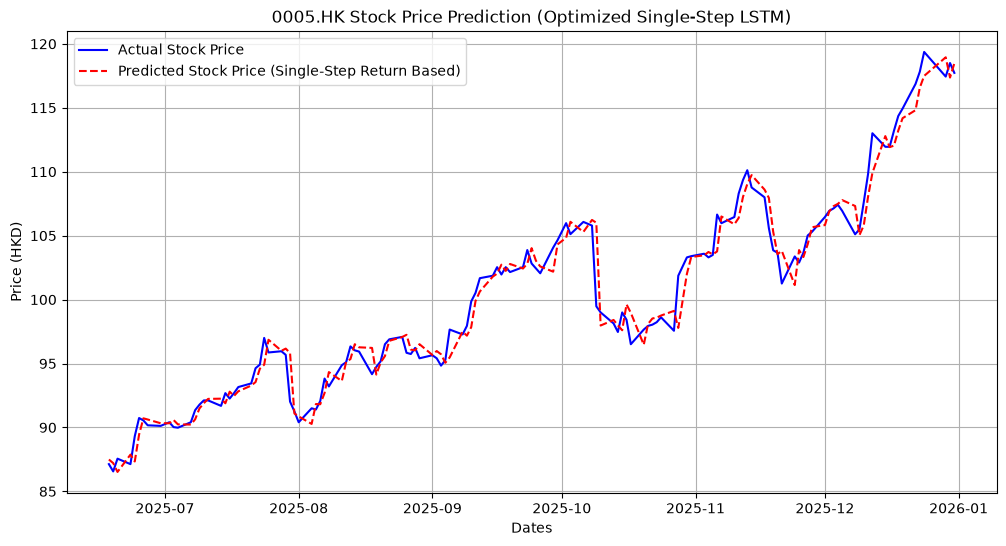

In [1]:
import warnings
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
import yfinance as yf

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")

#
company = "0005.HK"
df_HKstock = yf.download(company, start="2023-01-01", end="2026-01-01", auto_adjust=True)
df_source = df_HKstock.droplevel('Ticker', axis=1) if isinstance(df_HKstock.columns, pd.MultiIndex) else df_HKstock
df_source.index = pd.to_datetime(df_source.index)

# Data Preprocessing
df = df_source.copy()

# Calculate Moving Averages and Daily Returns
df['20-day MA'] = df['Close'].rolling(window=20).mean()
df['50-day MA'] = df['Close'].rolling(window=50).mean()
df['Daily Return'] = df['Close'].pct_change() # Stationary target feature, ideal for neural network training

# Drop rows with NaN values resulting from rolling window calculations
df = df.dropna()

# Shorten the lookback window to 30 days to reduce non-stationary noise
nb_days = 30 
test_days = 135

# Include Daily Return
df_target = df['Daily Return'].to_frame()

# Normalize the returns using StandardScaler to scale inputs and mitigate noise
scaler = StandardScaler()
scaled_returns = scaler.fit_transform(df_target)

#
def create_dataset(data, look_back=30):
    X, Y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i:(i + look_back), 0])
        Y.append(data[i + look_back, 0])
    return np.array(X), np.array(Y)

X, y = create_dataset(scaled_returns, look_back=nb_days)
X = np.reshape(X, (X.shape[0], X.shape[1], 1))

# Split training and testing sets chronologically 
train_size = len(X) - test_days
X_train, X_test = X[0:train_size], X[train_size:]
y_train, y_test = y[0:train_size], y[train_size:]

# Build LSTM Model
def build_tuned_lstm(input_shape):
    model = Sequential()
    # Layer 1: Bidirectional LSTM to capture forward and backward temporal context
    model.add(Bidirectional(LSTM(units=64, return_sequences=True), input_shape=input_shape))
    model.add(Dropout(0.3))
    
    # Layer 2: Standard LSTM to consolidate sequential features
    model.add(LSTM(units=32, return_sequences=False))
    model.add(Dropout(0.3))
    
    # Dense Layers
    model.add(Dense(units=16, activation='relu'))
    model.add(Dense(units=1)) # Outputs the single-step predicted return for the next day
    
   # Lower the learning rate to 0.0005 for stable convergence against noisy market data
    optimizer = Adam(learning_rate=0.0005)
    model.compile(optimizer=optimizer, loss='mse')
    return model

model = build_tuned_lstm((X_train.shape[1], 1))

# Implement Early Stopping to monitor validation loss and prevent overfitting
early_stop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

# Train the model while maintaining sequence chronological order (shuffle=False)
history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    shuffle=False
)

# Predict normalized returns for the test set
pred_scaled_returns = model.predict(X_test)
# Inverse transform predictions back to actual return scale
pred_returns = scaler.inverse_transform(pred_scaled_returns).flatten()
# Retrieve actual returns and historical closing prices for the test window
actual_returns = df_target.iloc[-test_days:].values.flatten()
actual_prices = df['Close'].iloc[-test_days-1:].values

# Reconstruct absolute prices: prevent cumulative errors from compounding
predicted_prices = []
for i in range(len(pred_returns)):
    prev_actual_price = actual_prices[i]
    pred_price = prev_actual_price * (1 + pred_returns[i])
    predicted_prices.append(pred_price)

predicted_prices = np.array(predicted_prices)
true_prices = actual_prices[1:]

# Evaluation : R² accuracy score for returns and reconstructed absolute prices
r2_returns = r2_score(actual_returns, pred_returns)
r2_prices = r2_score(true_prices, predicted_prices)

print("--- Model Evaluation Summary ---")
print(f"Returns Prediction R² Score: {r2_returns:.4f}")
print(f"Price Reconstruction R² Score: {r2_prices:.4f}")

# Plot actual vs predicted absolute stock prices
plt.figure(figsize=(12, 6))
plt.grid(True)
plt.plot(df.index[-test_days:], true_prices, 'b-', label='Actual Stock Price')
plt.plot(df.index[-test_days:], predicted_prices, 'r--', label='Predicted Stock Price (Single-Step Return Based)')
plt.title(f"{company} Stock Price Prediction (Optimized Single-Step LSTM)")
plt.xlabel('Dates')
plt.ylabel('Price (HKD)')
plt.legend()
plt.show()


In [2]:
import pickle
with open ('model.pk1', 'wb') as f:
    pickle.dump(model, f)

In [3]:
with open('model.pk1', 'rb') as f:
    loaded_model = pickle.load(f)

In [5]:
pred_scaled_returns = loaded_model.predict(X_test)
pred_returns = scaler.inverse_transform(pred_scaled_returns).flatten()
actual_returns = df_target.iloc[-test_days:].values.flatten()

r2_returns = r2_score(actual_returns, pred_returns)
r2_prices = r2_score(true_prices, predicted_prices)

print("--- Reloaded Model Summary ---")
print(f"Returns Prediction R² Score: {r2_returns:.4f}")
print(f"Price Reconstruction R² Score: {r2_prices:.4f}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
--- Reloaded Model Summary ---
Returns Prediction R² Score: -0.0104
Price Reconstruction R² Score: 0.9705
